# Capítulo 3 · Actividad: ¿qué hago con esta columna?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/04_actividad_decisiones_preprocesamiento.ipynb)

En las actividades anteriores te decíamos qué técnica aplicar. En la vida real nadie te lo dice: **tú decides**. En esta actividad vas a ver columnas de datasets que ya conoces y, para cada una, decidir qué es lo mejor: ¿one-hot u ordinal?, ¿logaritmo o no?, ¿estandarizar, min-max o nada?

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```

### Cómo trabajar

- En cada caso, **ejecuta la celda** que muestra los datos y **míralos con atención** antes de decidir.
- En las celdas ✍️ escribe **qué harías y por qué**. Una decisión sin justificación no vale.
- Algunos casos tienen una celda 🔍 **Comprueba** para verificar tu decisión con un par de líneas de código.
- Muchas veces no hay una única respuesta correcta, pero sí respuestas **mejor o peor justificadas**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

# Datasets que ya conoces
propinas = pd.read_csv(DATA_DIR / "tips.csv")
pinguinos = pd.read_csv(DATA_DIR / "penguins.csv").dropna()
california = pd.read_csv(DATA_DIR / "california_housing.csv")

# Viviendas, con la limpieza de las clases anteriores
viviendas = pd.read_csv(DATA_DIR / "viviendas_sucio.csv").drop_duplicates().dropna()
viviendas["barrio"] = viviendas["barrio"].str.strip().str.capitalize()

---
## Parte 1 · ¿Cómo convierto esta columna en números?

### Caso 1 · La isla de los pingüinos

In [2]:
pinguinos["island"].value_counts()

island
Biscoe       163
Dream        123
Torgersen     47
Name: count, dtype: int64

🤔 **Decide:** ¿cómo codificarías `island`: one-hot, ordinal o como binaria? ¿Por qué?

✍️ **Tu decisión:** 
One hot, debido a que son 3 categorias que ademas no tienen poderaciones que impliquen que una tenga mayor o menor importancia que la otra

In [8]:
pd.get_dummies(pinguinos["island"],prefix="isla",drop_first=True,dtype=int).value_counts()

isla_Dream  isla_Torgersen
0           0                 163
1           0                 123
0           1                  47
Name: count, dtype: int64

### Caso 2 · El estado de las viviendas

In [3]:
viviendas["estado"].value_counts()

estado
buen estado    220
a reformar     172
como nuevo     138
Name: count, dtype: int64

🤔 **Decide:** ¿cómo codificarías `estado`? Si eliges ordinal, indica qué número le darías a cada valor.

✍️ **Tu decisión:** Ordinal
- a reformar 1 
- buen estado 2 
- como nuevo 3

De esa forma forma sabria cuales tienen prioridad de reparacion

🔍 **Comprueba:** codifica `estado` como decidiste y muestra cuántas viviendas hay de cada valor codificado.

In [4]:
estado = {"a reformar":1,"buen estado":2, "como nuevo":3}
viviendas["estado"].map(estado).value_counts(dropna=False)

estado
2    220
1    172
3    138
Name: count, dtype: int64

### Caso 3 · ¿Fumadores en la mesa?

In [5]:
propinas["smoker"].value_counts()

smoker
No     151
Yes     93
Name: count, dtype: int64

🤔 **Decide:** ¿cuántas columnas necesitas para representar `smoker`? ¿Cómo la codificarías?

✍️ **Tu decisión:** Lo codificaria con binarios, debido a que solo se trata de un estado de si o no, por lo que lo mejor seria hacer eso, y por ello solo necesitaria de una columna

In [6]:
propinas["smoker"].map({"No":0,"Yes":1}).value_counts()

smoker
0    151
1     93
Name: count, dtype: int64

### Caso 4 · Personas en la mesa

In [9]:
propinas["size"].value_counts().sort_index()

size
1      4
2    156
3     38
4     37
5      5
6      4
Name: count, dtype: int64

🤔 **Decide:** `size` solo tiene 6 valores distintos. Un compañero propone tratarla como categórica y aplicarle one-hot. ¿Estás de acuerdo?

✍️ **Tu decisión:** Estoy de acuerdo con el manejo en categorico, ya que nos permitira manejar mesas de "pedidos grandes", superiores a 6 personas

### Caso 5 · El identificador

In [10]:
print("Filas:", len(viviendas), "| Valores distintos de id:", viviendas["id"].nunique())
viviendas[["id", "barrio", "precio"]].head()

Filas: 530 | Valores distintos de id: 530


,id,barrio,precio
0,404,Centro,372000.0
1,458,Sur,128400.0
2,501,Este,438200.0
3,85,Centro,309700.0
4,110,Oeste,306000.0


🤔 **Decide:** queremos predecir el precio. ¿Qué harías con la columna `id`?

✍️ **Tu decisión:** No la tomaria en cuenta, por lo que haria un drop, ya que no aporta informacion para la prediccion

In [12]:
viviendas.drop(columns="id").head()

,fecha_venta,barrio,metros,habitaciones,antiguedad,garaje,estado,distancia_metro_m,precio
0,2022-10-24,Centro,104.0,2,18.0,sí,buen estado,254.0,372000.0
1,2024-04-12,Sur,74.0,1,13.0,no,como nuevo,2369.0,128400.0
2,2023-09-12,Este,174.0,5,7.0,sí,como nuevo,1336.0,438200.0
3,2024-11-02,Centro,89.0,1,32.0,sí,a reformar,850.0,309700.0
4,2023-10-12,Oeste,114.0,4,0.0,no,como nuevo,379.0,306000.0


### Caso 6 · La fecha de venta

In [13]:
print("Filas:", len(viviendas), "| Fechas distintas:", viviendas["fecha_venta"].nunique())
viviendas["fecha_venta"].head()

Filas: 530 | Fechas distintas: 427


0    2022-10-24
1    2024-04-12
2    2023-09-12
3    2024-11-02
4    2023-10-12
Name: fecha_venta, dtype: str

🤔 **Decide:** un compañero propone aplicar one-hot a `fecha_venta`. ¿Qué pasaría? ¿Qué harías tú con esta columna?

✍️ **Tu decisión:** A primera vista, OneHot, estaria creando una columna por categoria, lo cual causaria bastantes problemas, ya que seria una tabla bastante extensa, en ese caso lo que haria seria la division de la fehca en año, mes y dia, lo cual permitiria en algun punto agruparlos por año, mes o dia, ademas de que hay que pasarlo de strings a datatime

🔍 **Comprueba:** crea a partir de `fecha_venta` las variables que propusiste.

In [15]:
from datetime import datetime
viviendas["fecha_venta"]=pd.to_datetime(viviendas["fecha_venta"])

In [21]:
viviendas["año_venta"]=viviendas["fecha_venta"].dt.year
viviendas["mes_venta"]=viviendas["fecha_venta"].dt.month
viviendas["dia_venta"]=viviendas["fecha_venta"].dt.day
viviendas[["fecha_venta","año_venta","mes_venta","dia_venta"]].head()

,fecha_venta,año_venta,mes_venta,dia_venta
0,2022-10-24,2022,10,24
1,2024-04-12,2024,4,12
2,2023-09-12,2023,9,12
3,2024-11-02,2024,11,2
4,2023-10-12,2023,10,12


### Caso 7 · El barrio y el modelo

In [22]:
viviendas["barrio"].value_counts()

barrio
Norte     120
Centro    114
Sur       112
Oeste     103
Este       81
Name: count, dtype: int64

🤔 **Decide:** vas a codificar `barrio` con one-hot.

a) Si el modelo es una **regresión lineal**, ¿usarías `drop_first=True`? ¿Y si es un **árbol de decisión**?

b) El modelo se usará después en una web donde se publicarán viviendas **de barrios nuevos** que no están en estos datos. ¿Usarías `pd.get_dummies` o `OneHotEncoder`? ¿Con qué parámetro?

✍️ **Tu decisión:** 

a) Si, creo que en ambos casos, podria usar el drop_firs=True, debido a que en ambos casos no representa un aumento de valor o importancia, aunque eso solo lo haria si considerase que no va a haber la integracion de un nuevo barrio

b) usaria OneHotEncoder ```OneHotEncoder(handle_unknown="ignore,sparse_output=False) ```

---
## Parte 2 · ¿La transformo?

### Caso 8 · Ingresos de los distritos de California

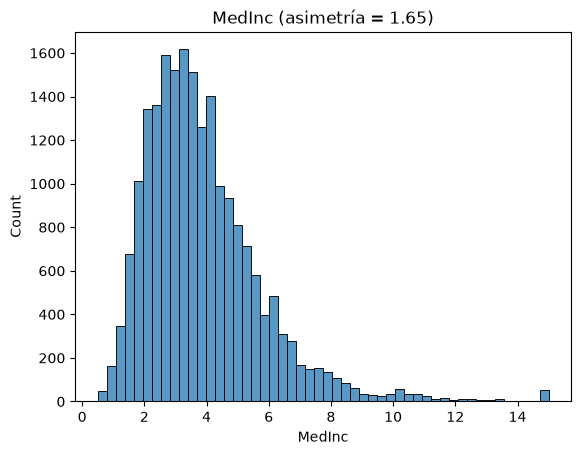

In [23]:
fig, ax = plt.subplots()
sns.histplot(california["MedInc"], bins=50, ax=ax)
ax.set_title(f"MedInc (asimetría = {california['MedInc'].skew():.2f})")
plt.show()

🤔 **Decide:** ¿le aplicarías un logaritmo a `MedInc`? ¿Por qué?

✍️ **Tu decisión:** 
Si lo haria, debido a que la distribucion de los datos, se encuentra enfocada hacia el lado izquierdo

🔍 **Comprueba:** calcula la asimetría de `MedInc` después de aplicarle `np.log1p`.

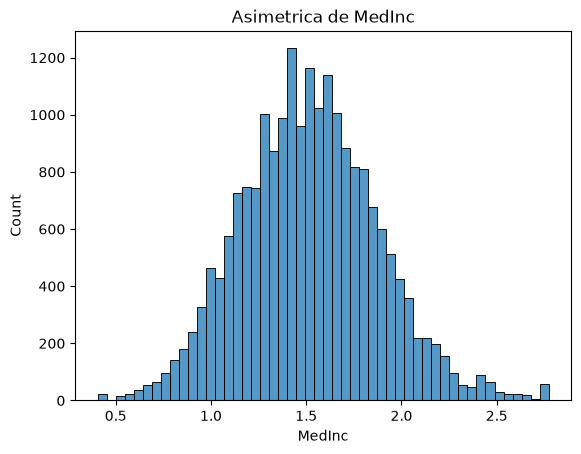

In [25]:
asimetria=np.log1p(california["MedInc"])
fig,ax = plt.subplots()
sns.histplot(asimetria,bins=50,ax=ax)
ax.set_title("Asimetrica de MedInc")
plt.show()

### Caso 9 · La aleta de los pingüinos

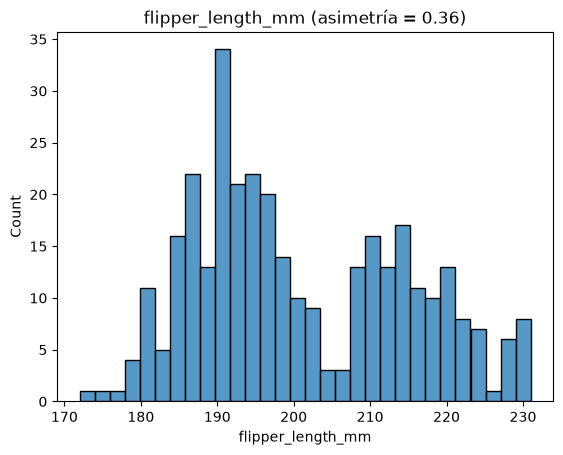

In [26]:
fig, ax = plt.subplots()
sns.histplot(pinguinos["flipper_length_mm"], bins=30, ax=ax)
ax.set_title(f"flipper_length_mm (asimetría = {pinguinos['flipper_length_mm'].skew():.2f})")
plt.show()

🤔 **Decide:** el histograma no parece una campana: tiene dos "montañas". ¿Le aplicarías un logaritmo? ¿Por qué crees que tiene esa forma?

✍️ **Tu decisión:** 

No considero necesario aplicarle el logaritmo, sobre todo porque se puede tratar de una variacion mas relacionada con las especies, que con caracteristicas anormales en la informacion.

### Caso 10 · Variables nuevas para California

Queremos predecir `MedHouseVal` (el valor de las viviendas). Un compañero propone crear estas tres variables:

| Variable | Fórmula |
|---|---|
| `habitaciones_por_persona` | `AveRooms / AveOccup` |
| `valor_por_habitacion` | `MedHouseVal / AveRooms` |
| `proporcion_dormitorios` | `AveBedrms / AveRooms` |

🤔 **Decide:** ¿cuáles de las tres se pueden usar en el modelo? ¿Por qué?

✍️ **Tu decisión:** 

De las propuestas solo podemos usar habitaciones_por_persona y proporcion_dormitorios, debido a que son las unicas variables que no utilizan el valor a pronosticar como caracteristica derivadas, por lo que no alterarian directamente el modelo

### Caso 11 · La antigüedad de las viviendas

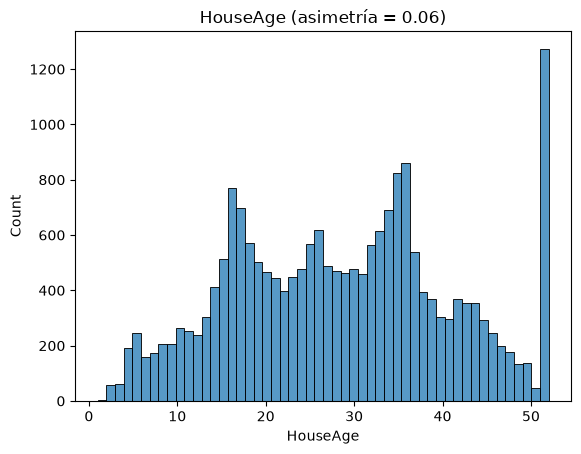

In [28]:
fig, ax = plt.subplots()
sns.histplot(california["HouseAge"], bins=52, ax=ax)
ax.set_title(f"HouseAge (asimetría = {california['HouseAge'].skew():.2f})")
plt.show()

🤔 **Decide:** ¿agruparías `HouseAge` en tramos ("nueva", "media", "antigua") o la dejarías numérica? ¿Le aplicarías un logaritmo?

✍️ **Tu decisión:** 

Seria bueno agruparlas en tramos de nueva, media( >15 años) y antigua ( >35 años), el algoritmo no lo considero necesario, por que a pesar de que no forma completamente la curva gaussiana, no se trata de una variacion de datos extrema.

---
## Parte 3 · ¿Escalo? ¿Cómo?

### Caso 12 · Clasificar pingüinos con KNN

Queremos predecir la especie con **KNN**, un modelo que clasifica cada pingüino según los pingüinos **más cercanos** (calcula distancias entre sus medidas).

In [32]:
pinguinos[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]].describe().loc[["mean", "std", "min", "max"]].round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
mean,44.0,17.2,201.0,4207.1
std,5.5,2.0,14.0,805.2
min,32.1,13.1,172.0,2700.0
max,59.6,21.5,231.0,6300.0


🤔 **Decide:** ¿escalarías estas medidas? Si sí, ¿con qué método? ¿Qué pasaría si no las escalas?

✍️ **Tu decisión:** 

Si las escalaria, por el modelo a utilizar, y lo haria con normalizacion, si no las escalo, puede que el modelo no sea efectivo.

### Caso 13 · Los mismos pingüinos con un árbol de decisión

Ahora usamos un **árbol de decisión**, que clasifica haciendo preguntas del tipo *"¿la aleta mide más de 206 mm?"*.

🤔 **Decide:** ¿hace falta escalar las medidas? ¿Por qué?

✍️ **Tu decisión:** 

No es necesario, pero no le viene mal una estandarizacion, que permita manejar mas rapido la informacion

### Caso 14 · Imágenes para una red neuronal

Una red neuronal recibe imágenes en escala de grises. Cada píxel es un número de **0 (negro) a 255 (blanco)**:

In [33]:
pixeles = np.random.default_rng(42).integers(0, 256, size=(4, 6))
pixeles

array([[ 22, 198, 167, 112, 110, 219],
       [ 22, 178,  51,  24, 134, 249],
       [188, 194, 183, 201, 131,  32],
       [214, 115, 128,  94,  46, 237]])

🤔 **Decide:** ¿qué escalado usarías: estandarización o min-max? ¿Por qué?

✍️ **Tu decisión:** 

Por medio de MinMax, ya que se requiere el manejo de un rango fijo desde 0 hasta 1

### Caso 15 · ¿Escalo también las categóricas?

Tras codificar las viviendas, tienes columnas de este tipo:

In [34]:
pd.concat([
    viviendas[["metros", "distancia_metro_m"]],
    pd.get_dummies(viviendas["barrio"], prefix="barrio", dtype=int),
    viviendas["garaje"].map({"no": 0, "sí": 1}).rename("garaje"),
], axis=1).head()

,metros,distancia_metro_m,barrio_Centro,barrio_Este,barrio_Norte,barrio_Oeste,barrio_Sur,garaje
0,104.0,254.0,1,0,0,0,0,1
1,74.0,2369.0,0,0,0,0,1,0
2,174.0,1336.0,0,1,0,0,0,1
3,89.0,850.0,1,0,0,0,0,1
4,114.0,379.0,0,0,0,1,0,0


🤔 **Decide:** vas a estandarizar. ¿Lo aplicarías a **todas** las columnas, también a las de one-hot y a `garaje`? ¿Por qué?

✍️ **Tu decisión:** 

No, no las estandarizaria todas, ya que las one hot y garaje tienen valores binarios, lo cual me facilitaria su manejo en el modelo

### Caso 16 · ¿En qué orden?

Dos compañeros escriben este código para preparar los datos:

**Compañero A:**
```python
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_escalado, y, test_size=0.2, random_state=42)
```

**Compañero B:**
```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.fit_transform(X_test)
```

🤔 **Decide:** ¿alguno lo hace bien? Explica qué falla en cada uno y escribe (en palabras o en código) el orden correcto.

✍️ **Tu decisión:** 

- Compañero A: A pesar de realiar el escalado, no se ve que se indentifiquen los valores del target para el entrenamiento, a menos que haya sido un paso previo, ademas de que no sabemos si en verdad estandarizo solo las variables a ocupar, mas que otra cosa por el tiempo de procesamiento

- Compañero B: De igual forma, no se visualiza en que momento se escoge la informacion del target, o si se seleccionan los valores correctos para el entrenamiento.

---
## Parte 4 · Diseña el preprocesamiento completo

Queremos predecir la **propina** (`tip`) con una **regresión lineal**, a partir del resto de columnas de `propinas`.

In [38]:
print(propinas.drop(columns=["tip"]).skew(numeric_only=True).round(2))
propinas.head()
propinas.info()

total_bill    1.13
size          1.45
dtype: float64
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


🤔 **Decide:** completa la tabla con el tratamiento de cada columna y añade, si quieres, alguna variable nueva. Justifica las decisiones que no sean obvias.

| Columna | Tipo | Transformación | Codificación | Escalado |
|---|---|---|---|---|
| `total_bill` || || |
| `sex` ||| | |
| `smoker` | | | | |
| `day` | | | | |
| `time` | | | | |
| `size` | | | | |
| *(variable nueva)* | | | | |

✍️ **Tu decisión:** 

| Columna | Tipo | Transformación | Codificación | Escalado |
|---|---|---|---|---|
| `total_bill` |float64 |ninguna |ninguna |estandarizacion|
| `sex` |str |ninguna |binaria |ninguna |
| `smoker` |str |ninguna |binaria |ninguna |
| `day` |str |ninguna |OneHot |ninguna |
| `time` |str |ninguna |OneHot |ninguna |
| `size` |int64 |ninguna |OneHot |ninguna |
| *bill_per_person* |float64 |round(2) |ninguna |estandarizacion |